# Data Overview

This analysis uses the Daily Electricity Price and Demand dataset. The dataset covers 2016 days between 1 January 2015 and 6 October 2020.

Each row represents a day, containing Demand, RRP (Recommended Retail Price), RRP Positive, RRP Negative...

Our goal here is to understand the data - columns, data types, missing values, duplicates, etc.

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../data/raw/complete_dataset.csv')

## Understanding the Data

In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 2106 entries, 0 to 2105
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   date             2106 non-null   str    
 1   demand           2106 non-null   float64
 2   RRP              2106 non-null   float64
 3   demand_pos_RRP   2106 non-null   float64
 4   RRP_positive     2106 non-null   float64
 5   demand_neg_RRP   2106 non-null   float64
 6   RRP_negative     2106 non-null   float64
 7   frac_at_neg_RRP  2106 non-null   float64
 8   min_temperature  2106 non-null   float64
 9   max_temperature  2106 non-null   float64
 10  solar_exposure   2105 non-null   float64
 11  rainfall         2103 non-null   float64
 12  school_day       2106 non-null   str    
 13  holiday          2106 non-null   str    
dtypes: float64(11), str(3)
memory usage: 230.5 KB


The dataset contains 14 columns, 2106 rows. Solar Exposure and Rainfall are the only columns that contain a small amount of non-null values.

There are 3 string data types, and 11 float data types. From first look:
- Date should be transformed to Date type
- School Day and Holiday should be transformed to Booleans

## Unique Values

In [4]:
df.nunique()

date               2106
demand             2106
RRP                2106
demand_pos_RRP     2106
RRP_positive       2106
demand_neg_RRP      192
RRP_negative        179
frac_at_neg_RRP      21
min_temperature     211
max_temperature     283
solar_exposure      316
rainfall            105
school_day            2
holiday               2
dtype: int64

In [5]:
school_day_unique = df['school_day'].unique()
holiday_unique = df['holiday'].unique()

print(school_day_unique)
print(holiday_unique)

<StringArray>
['N', 'Y']
Length: 2, dtype: str
<StringArray>
['Y', 'N']
Length: 2, dtype: str


## Descriptive Statistics

In [16]:
df.describe()

,demand,RRP,demand_pos_RRP,RRP_positive,demand_neg_RRP,RRP_negative,frac_at_neg_RRP,min_temperature,max_temperature,solar_exposure,rainfall
count,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2105.000000,2103.000000
mean,120035.476503,76.079554,119252.305055,76.553847,783.171448,-2.686052,0.008547,11.582289,20.413200,14.743373,1.505944
std,13747.993761,130.246805,14818.631319,130.114184,3578.920686,19.485432,0.039963,4.313711,6.288693,7.945527,4.307897
min,85094.375000,-6.076028,41988.240000,13.568986,0.000000,-342.220000,0.000000,0.600000,9.000000,0.700000,0.000000
25%,109963.650000,38.707040,109246.250000,39.117361,0.000000,0.000000,0.000000,8.500000,15.525000,8.200000,0.000000
50%,119585.912500,66.596738,119148.082500,66.869058,0.000000,0.000000,0.000000,11.300000,19.100000,12.700000,0.000000
75%,130436.006250,95.075012,130119.477500,95.130181,0.000000,0.000000,0.000000,14.600000,23.900000,20.700000,0.800000
max,170653.840000,4549.645105,170653.840000,4549.645105,57597.595000,0.000000,0.625000,28.000000,43.500000,33.300000,54.600000


## Missing Values and Duplicates

In [6]:
duplicates = df.duplicated().sum()

print(f'Number of duplicates: {duplicates}')

Number of duplicates: 0


In [7]:
missing_values = df.isna().sum()

print(f'Number of missing values:\n{missing_values}')

Number of missing values:
date               0
demand             0
RRP                0
demand_pos_RRP     0
RRP_positive       0
demand_neg_RRP     0
RRP_negative       0
frac_at_neg_RRP    0
min_temperature    0
max_temperature    0
solar_exposure     1
rainfall           3
school_day         0
holiday            0
dtype: int64


From the list we can see there is only 1 missing Solar Exposure value, and 3 missing Rainfall values.
There are also 0 duplicates.

### Missing Values Distribution

Text(0, 0.5, 'Number of Values')

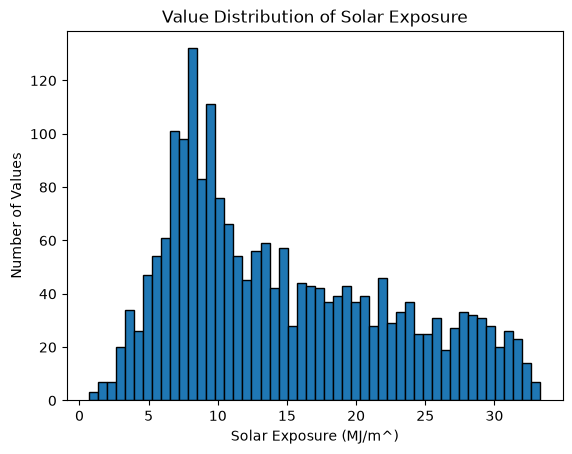

In [8]:
plt.hist(df['solar_exposure'].dropna(), bins=50, edgecolor='black')

plt.title('Value Distribution of Solar Exposure')
plt.xlabel('Solar Exposure (MJ/m^)')
plt.ylabel('Number of Values')

Text(0, 0.5, 'Number of Values')

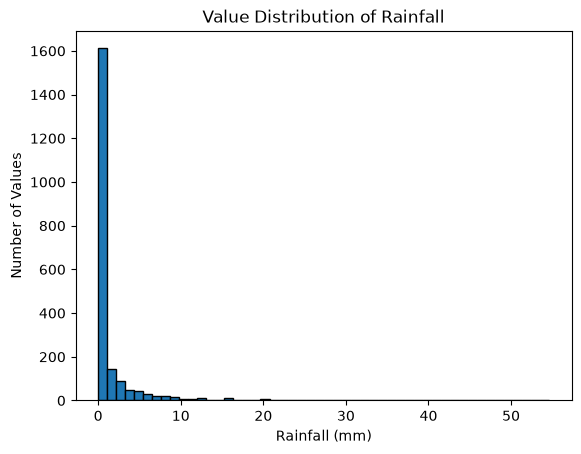

In [9]:
plt.hist(df['rainfall'].dropna(), bins=50, edgecolor='black')

plt.title('Value Distribution of Rainfall')
plt.xlabel('Rainfall (mm)')
plt.ylabel('Number of Values')

The distributions will help us later when we need to replace missing values.

## Correlation

In [18]:
df.corr(numeric_only=True)

,demand,RRP,demand_pos_RRP,RRP_positive,demand_neg_RRP,RRP_negative,frac_at_neg_RRP,min_temperature,max_temperature,solar_exposure,rainfall
demand,1.000000,0.217538,0.971377,0.215038,-0.180638,0.057854,-0.189839,-0.156118,-0.073216,-0.257406,-0.064609
RRP,0.217538,1.000000,0.220856,0.999821,-0.078815,0.038931,-0.077955,0.070619,0.165484,0.061808,-0.028642
demand_pos_RRP,0.971377,0.220856,1.000000,0.214628,-0.409102,0.120054,-0.416573,-0.147020,-0.068146,-0.229749,-0.069696
RRP_positive,0.215038,0.999821,0.214628,1.000000,-0.062631,0.029455,-0.061968,0.071052,0.165663,0.061311,-0.027860
demand_neg_RRP,-0.180638,-0.078815,-0.409102,-0.062631,1.000000,-0.274847,0.995590,0.009030,0.000914,-0.037467,0.040387
RRP_negative,0.057854,0.038931,0.120054,0.029455,-0.274847,1.000000,-0.258065,-0.077248,-0.033255,0.001654,-0.020794
frac_at_neg_RRP,-0.189839,-0.077955,-0.416573,-0.061968,0.995590,-0.258065,1.000000,0.008859,-0.001174,-0.036701,0.038527
min_temperature,-0.156118,0.070619,-0.147020,0.071052,0.009030,-0.077248,0.008859,1.000000,0.705433,0.376261,-0.003050
max_temperature,-0.073216,0.165484,-0.068146,0.165663,0.000914,-0.033255,-0.001174,0.705433,1.000000,0.598995,-0.155392
solar_exposure,-0.257406,0.061808,-0.229749,0.061311,-0.037467,0.001654,-0.036701,0.376261,0.598995,1.000000,-0.123568
